# 5. Explicabilité du CNN : Dataset 2 (extrait final, 60 000 images)

Grad-CAM, feature maps et SHAP sur le CNN de 4.3, rechargé tel quel (rien n'est ré-entraîné). Lancer
`4.3_cnn.ipynb` avant.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")  # avertissement tqdm sans importance

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import timm
import torch
from PIL import Image
from torchvision import transforms

CLASSES = ["email", "form", "invoice", "presentation", "resume", "scientific_report"]
ARTEFACTS = "../data/artifacts_rvl_cdip_filtered_dataset_3"
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# le CNN de 4.3, avec le même pré-traitement
model = timm.create_model("efficientnet_b0", pretrained=False, num_classes=6)
model.load_state_dict(torch.load(f"{ARTEFACTS}/etape5_cnn_model.pt", map_location="cpu"))
model = model.to(device).eval()

normalisation = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # comme ImageNet
transform_eval = transforms.Compose([transforms.Resize((384, 384)), transforms.ToTensor(), normalisation])

# ses prédictions sur le test (vraie classe = nom du dossier)
probas = pd.read_parquet(f"{ARTEFACTS}/probas_cnn_test.parquet")
test = pd.DataFrame({"filepath": probas["filepath"],
                     "label": probas["filepath"].str.split("/").str[-2],
                     "pred": probas[CLASSES].idxmax(axis=1),
                     "confiance": probas[CLASSES].max(axis=1)})
print(f"Test : {len(test)} documents, accuracy du CNN : {(test['label'] == test['pred']).mean():.1%}")

Test : 2394 documents, accuracy du CNN : 85.1%


## 5.1 Grad-CAM

On suit les étapes du cours :
1. un hook récupère la sortie d'une couche de convolution ;
2. on calcule le gradient du score de la classe par rapport à cette sortie ;
3. chaque filtre est pondéré par la moyenne de son gradient, on additionne et on garde le positif ;
4. on agrandit la carte (12 × 12 pour la dernière couche) et on la pose sur le document.

In [2]:
def load_image(filepath):
    return Image.open("../" + filepath).convert("RGB")


def grad_cam(filepath, layer_name="conv_head", classe=None):
    """carte Grad-CAM entre 0 et 1, pour la classe prédite si on n'en donne pas"""
    x = transform_eval(load_image(filepath)).unsqueeze(0).to(device)

    # 1. le hook attrape la sortie de la couche
    saved = {}
    def forward_hook(module, input, output):
        saved["activations"] = output
    hook = model.get_submodule(layer_name).register_forward_hook(forward_hook)
    output = model(x)
    hook.remove()
    class_idx = output.argmax(dim=1).item() if classe is None else CLASSES.index(classe)

    # 2. gradients du score de la classe sur cette sortie
    model.zero_grad()
    saved["activations"].retain_grad()
    output[0, class_idx].backward()
    gradients, activations = saved["activations"].grad[0], saved["activations"][0]

    # 3. un poids par filtre, on additionne, on garde le positif, on ramène entre 0 et 1
    pooled_grads = gradients.mean(dim=(1, 2))
    heatmap = torch.relu((pooled_grads[:, None, None] * activations).sum(dim=0))
    heatmap = (heatmap / (heatmap.max() + 1e-8)).detach().cpu().numpy()

    proba = torch.softmax(output, dim=1)[0, class_idx].item()
    return heatmap, CLASSES[class_idx], proba


def show_document(ax, filepath, titre, heatmap=None):
    """le document, avec la carte par-dessus si on en donne une"""
    ax.imshow(load_image(filepath).resize((384, 384)))
    if heatmap is not None:  # 4. la carte par-dessus, étirée à la taille du document
        ax.imshow(heatmap, cmap="jet", alpha=0.45, interpolation="bilinear", extent=(*ax.get_xlim(), *ax.get_ylim()))
    ax.set_title(titre, fontsize=10)
    ax.axis("off")

### Un document bien classé par classe

Pour chaque classe, le document bien classé avec la plus grande confiance. Carte calculée sur la
dernière couche (`conv_head`).

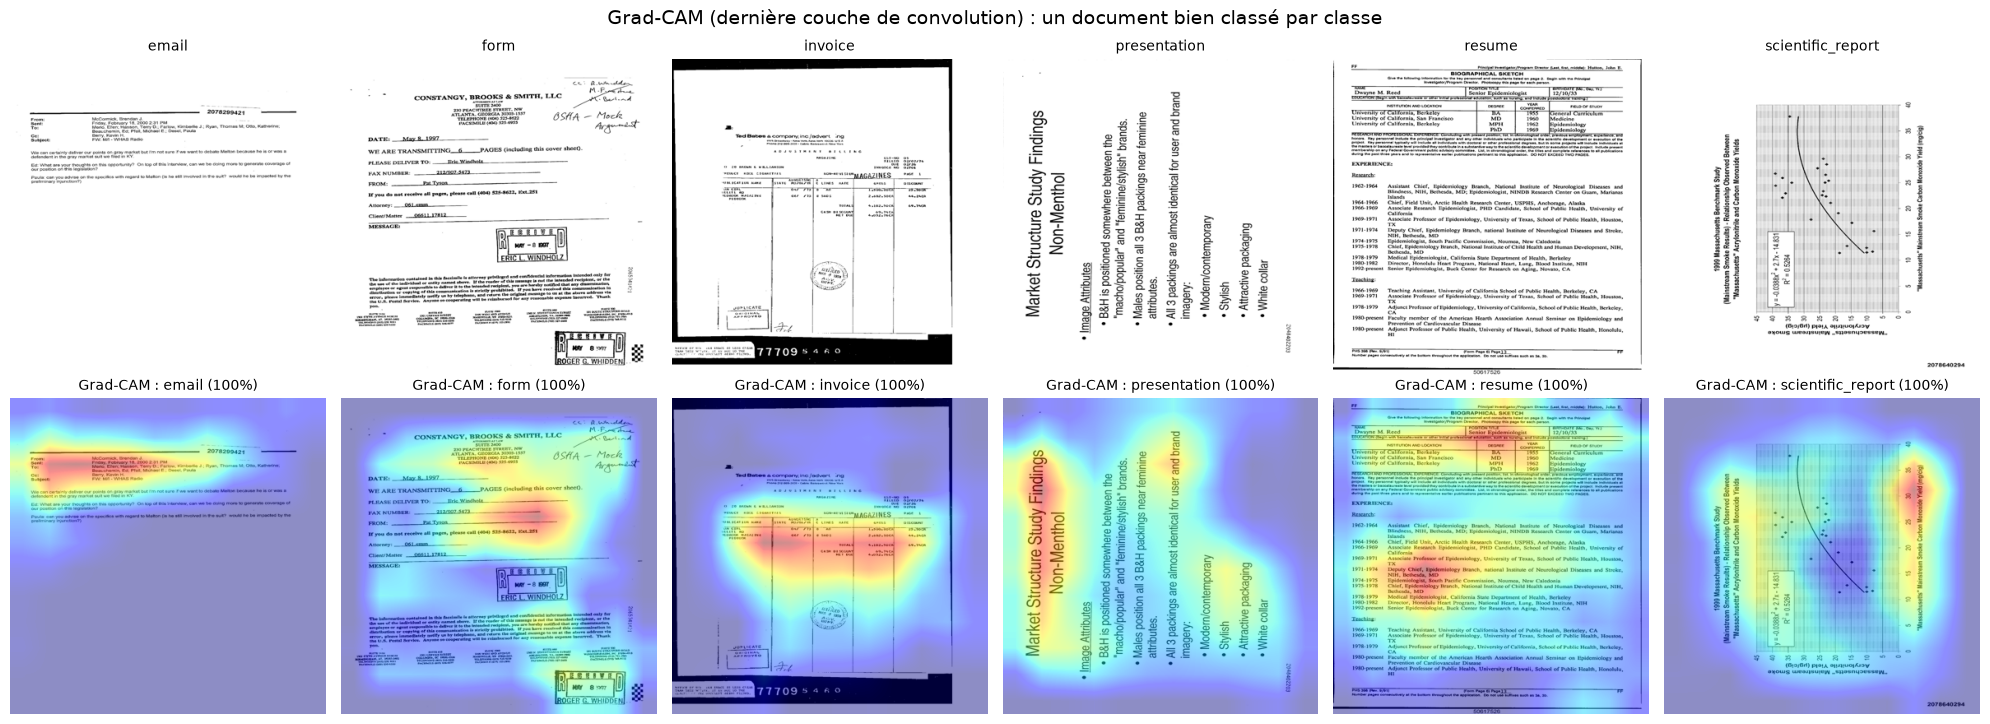

In [3]:
justes = test[test["label"] == test["pred"]]
exemples = justes.loc[justes.groupby("label")["confiance"].idxmax()].set_index("label")["filepath"]

fig, axes = plt.subplots(2, 6, figsize=(20, 7.5))
for j, classe in enumerate(CLASSES):
    heatmap, classe_predite, proba = grad_cam(exemples[classe])
    show_document(axes[0, j], exemples[classe], classe)
    show_document(axes[1, j], exemples[classe], f"Grad-CAM : {classe_predite} ({proba:.0%})", heatmap)
fig.suptitle("Grad-CAM (dernière couche de convolution) : un document bien classé par classe", fontsize=14)
plt.tight_layout()
plt.show()

La zone rouge tombe sur le bloc typique de chaque classe : en-tête de l'e-mail, champs du formulaire,
tableaux de la facture et du CV, liste à puces, graphique du rapport. Rien ne s'allume sur les marges
noires du scan.

### D'une couche à l'autre

Grad-CAM sur trois couches, du début (`blocks.1`) à la fin (`conv_head`), puis les feature maps de la
première convolution (`conv_stem`).

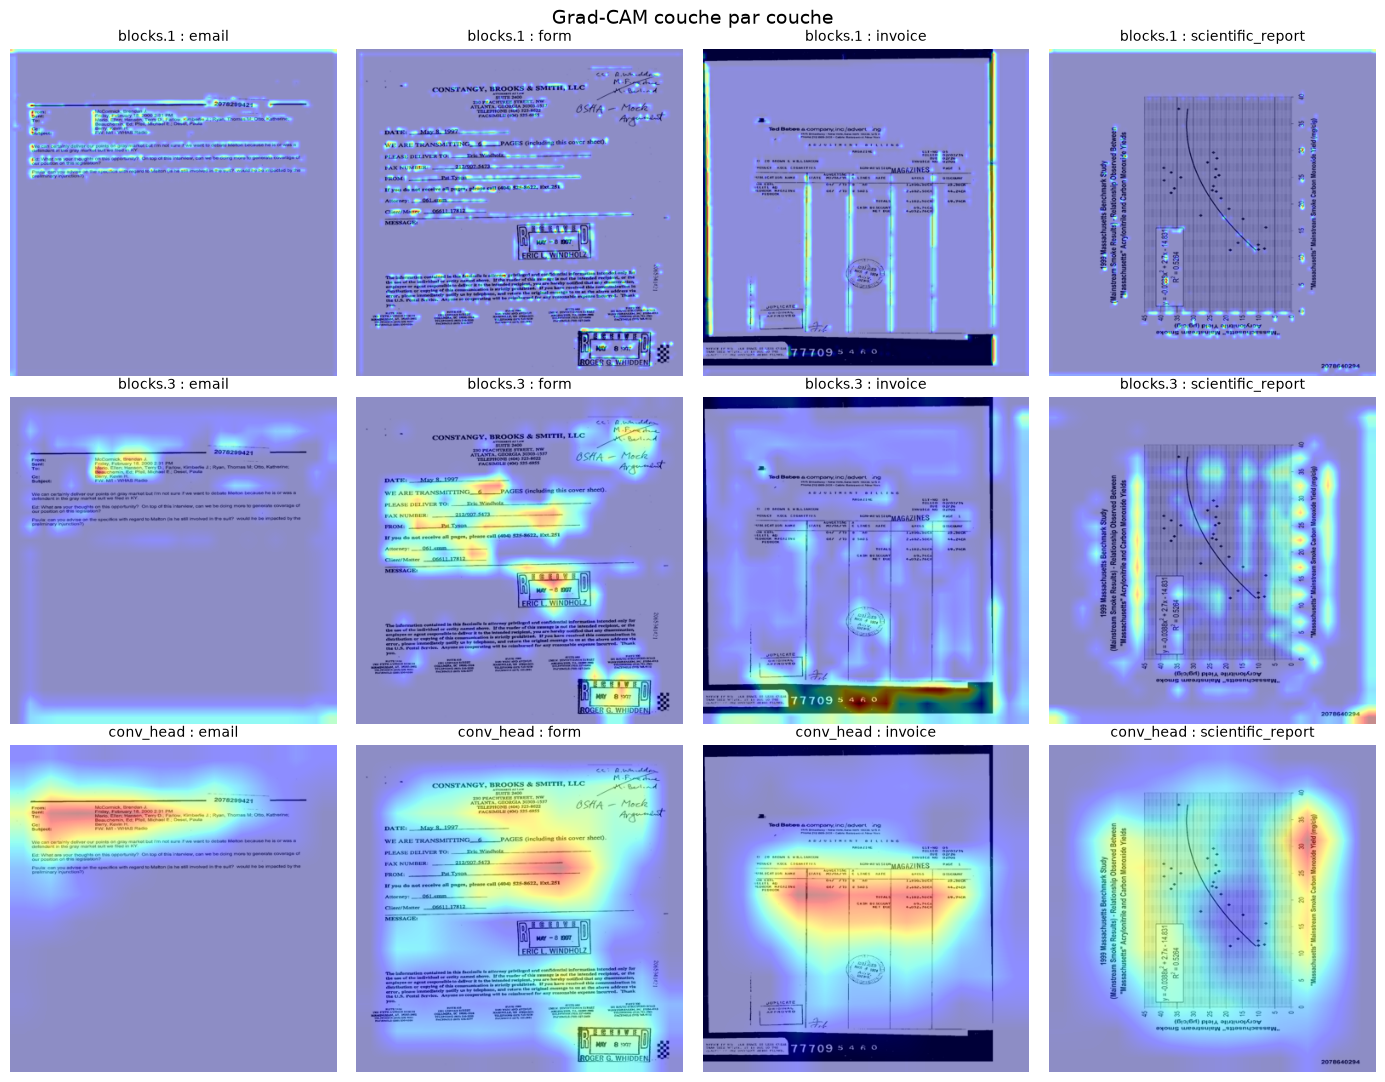

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for i, couche in enumerate(["blocks.1", "blocks.3", "conv_head"]):
    for j, classe in enumerate(["email", "form", "invoice", "scientific_report"]):
        heatmap, classe_predite, _ = grad_cam(exemples[classe], layer_name=couche)
        show_document(axes[i, j], exemples[classe], f"{couche} : {classe_predite}", heatmap)
fig.suptitle("Grad-CAM couche par couche", fontsize=14)
plt.tight_layout()
plt.show()

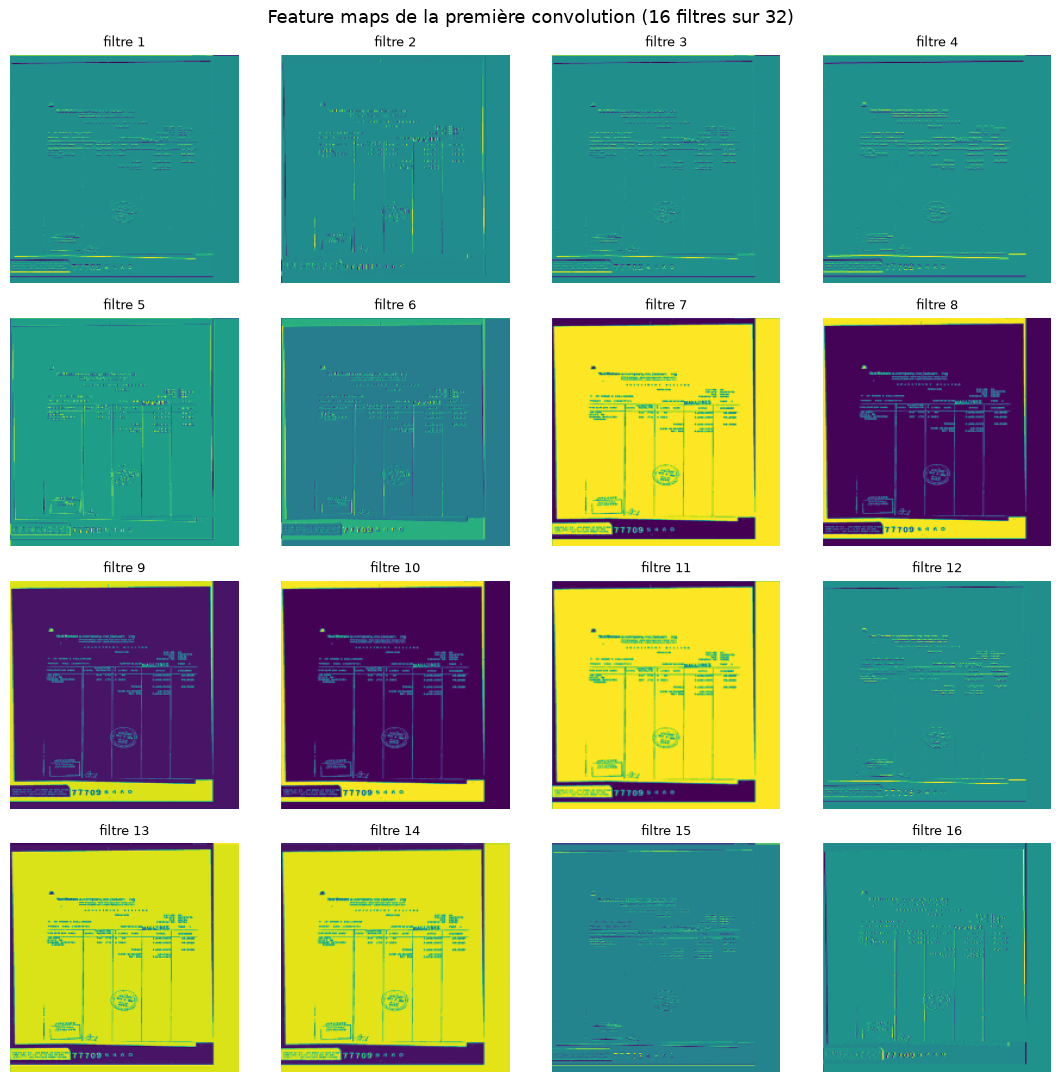

In [5]:
# ce que sortent 16 filtres de la 1re convolution, sur la facture
x = transform_eval(load_image(exemples["invoice"])).unsqueeze(0).to(device)
with torch.no_grad():
    feature_maps = model.conv_stem(x)[0].cpu()

fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[i], cmap="viridis")
    ax.set_title(f"filtre {i + 1}", fontsize=9)
    ax.axis("off")
fig.suptitle("Feature maps de la première convolution (16 filtres sur 32)", fontsize=13)
plt.tight_layout()
plt.show()

Plus on avance dans le réseau, plus les motifs sont gros : des traits (lignes de texte, filets), puis
des éléments de la page (champs remplis, tampon), puis des blocs entiers. Les marges noires ressortent
au début, plus à la fin.

### Quand le CNN se trompe

Pour trois confusions, on prend l'erreur où le CNN était le plus sûr de lui et on affiche deux cartes :
classe prédite et vraie classe.

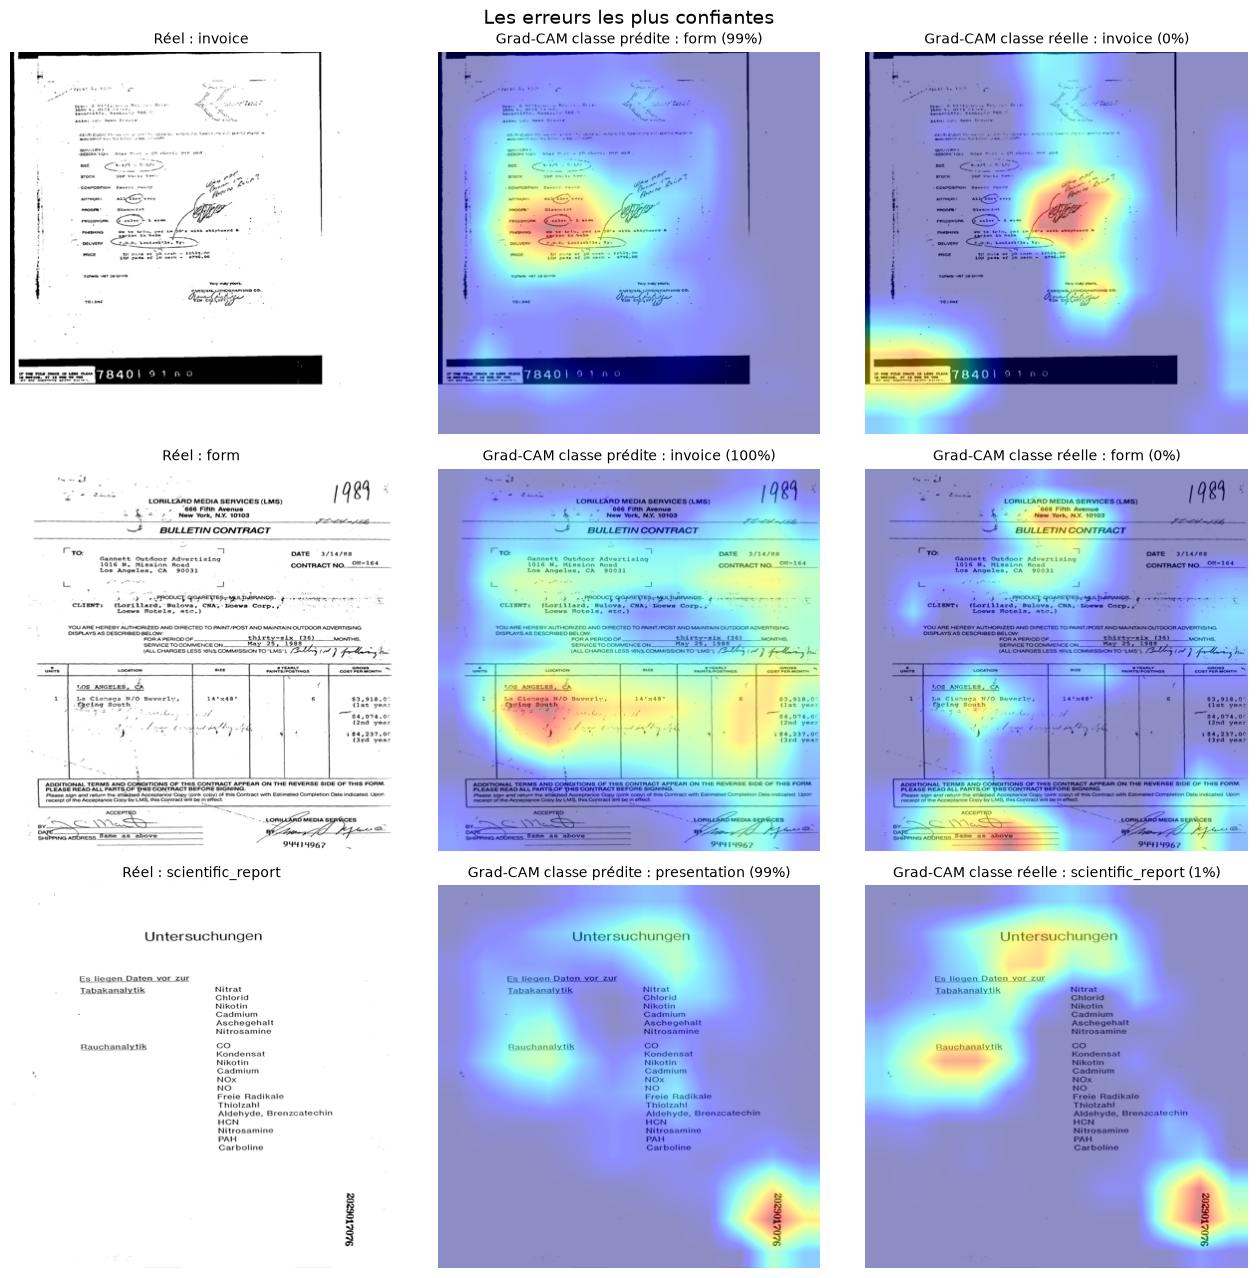

In [6]:
erreurs = {}
for reelle, predite in [("invoice", "form"), ("form", "invoice"), ("scientific_report", "presentation")]:
    candidats = test[(test["label"] == reelle) & (test["pred"] == predite)]
    erreurs[reelle, predite] = candidats.loc[candidats["confiance"].idxmax(), "filepath"]

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
for i, ((reelle, predite), filepath) in enumerate(erreurs.items()):
    carte_predite, _, proba_predite = grad_cam(filepath)
    carte_reelle, _, proba_reelle = grad_cam(filepath, classe=reelle)
    show_document(axes[i, 0], filepath, f"Réel : {reelle}")
    show_document(axes[i, 1], filepath, f"Grad-CAM classe prédite : {predite} ({proba_predite:.0%})", carte_predite)
    show_document(axes[i, 2], filepath, f"Grad-CAM classe réelle : {reelle} ({proba_reelle:.0%})", carte_reelle)
fig.suptitle("Les erreurs les plus confiantes", fontsize=14)
plt.tight_layout()
plt.show()

Le CNN regarde bien la zone qui pose problème (colonne libellé-valeur, tableau de montants) : il
faudrait lire les mots pour trancher.

Pour le rapport scientifique, la carte s'accroche en partie au numéro imprimé dans la marge : c'est le
seul biais repéré.

## 5.2 SHAP

SHAP cache des morceaux de l'image et regarde l'effet sur le score de chaque classe (rouge : pousse
vers la classe, bleu : l'en éloigne). Une zone cachée est remplie avec ses voisines (`inpaint_telea`),
et on explique les scores avant softmax, sinon à 100 % tout est presque nul.

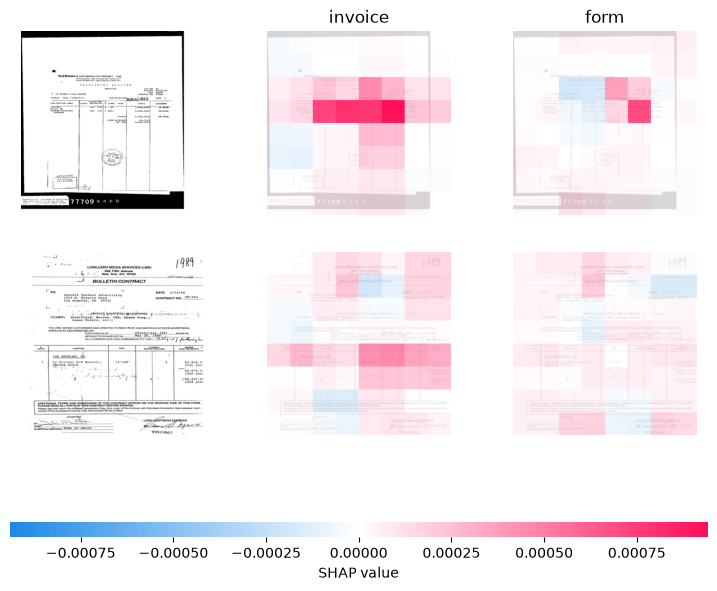

In [7]:
def predict_scores(images):
    """pour SHAP : images numpy (0 à 255) en entrée, scores des 6 classes en sortie"""
    x = torch.as_tensor(images, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    with torch.no_grad():
        return model(normalisation(x).to(device)).cpu().numpy()


documents = [exemples["invoice"], erreurs["form", "invoice"]]
X = np.stack([np.array(load_image(f).resize((384, 384)), dtype=np.float32) for f in documents])

masker = shap.maskers.Image("inpaint_telea", X[0].shape)
explainer = shap.Explainer(predict_scores, masker, output_names=CLASSES)
shap_values = explainer(X, max_evals=500, batch_size=16, silent=True,
                        outputs=shap.Explanation.argsort.flip[:2])  # les 2 classes les plus probables
shap_values.data = shap_values.data / 255  # image_plot veut une image entre 0 et 1
shap.image_plot(shap_values)

Même chose qu'avec Grad-CAM : c'est le tableau qui pousse vers `invoice`.

## 5.3 Constat

- Le CNN se base sur la mise en page.
- Facture et formulaire se ressemblent vraiment : il lui faudrait les mots pour trancher.
- Il est trop sûr de lui, même quand il se trompe.
- Ce ne sont que quelques exemples (6 bien classés, 3 erreurs, 2 pour SHAP).